In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Library berhasil disiapkan!")

Library berhasil disiapkan!


In [ ]:
np.random.seed(42)

jumlah_data = 300

jenis_penyebab = [
    "Pertanian",
    "Pertambangan",
    "Penebangan",
    "Pembangunan jalan",
    "Kebakaran",
    "Gangguan alami"
]

data = []

for i in range(jumlah_data):
    penyebab = np.random.choice(jenis_penyebab)

    data.append({
        "id_alert": f"AL-{i+1:04d}",
        "wilayah": np.random.choice([
            "Sumatra", "Kalimantan", "Papua", "Sulawesi"
        ]),
        "luas_gangguan_ha": round(np.random.uniform(1, 100), 2),
        "kehilangan_kanopi_pct": round(np.random.uniform(10, 100), 2),
        "jarak_jalan_km": round(np.random.uniform(0, 20), 2),
        "confidence": round(np.random.uniform(0.50, 1.00), 2),
        "penyebab": penyebab
    })

df = pd.DataFrame(data)

display(df.head(10))

print("Jumlah data:", len(df))
print("Jumlah kolom:", len(df.columns))

,id_alert,wilayah,luas_gangguan_ha,kehilangan_kanopi_pct,jarak_jalan_km,confidence,penyebab
0,AL-0001,Sumatra,19.16,80.17,11.94,0.72,Pembangunan jalan
1,AL-0002,Papua,86.75,64.10,14.16,0.51,Penebangan
2,AL-0003,Sulawesi,83.41,29.11,3.64,0.59,Pertambangan
3,AL-0004,Kalimantan,52.95,48.88,5.82,0.81,Pembangunan jalan
4,AL-0005,Sulawesi,29.92,42.97,9.12,0.89,Pertambangan
5,AL-0006,Sulawesi,51.91,63.32,0.93,0.80,Penebangan
6,AL-0007,Sumatra,7.44,95.40,19.31,0.90,Kebakaran
7,AL-0008,Kalimantan,10.67,71.58,8.80,0.56,Pertanian
8,AL-0009,Sulawesi,4.40,91.84,5.18,0.83,Kebakaran
9,AL-0010,Kalimantan,52.49,59.20,3.70,0.98,Pertambangan


Jumlah data: 300
Jumlah kolom: 7


In [ ]:
# Melihat ukuran dataset
print("Ukuran dataset:", df.shape)

# Memeriksa tipe data dan kelengkapan data
print("\nInformasi dataset:")
df.info()

# Memeriksa data kosong
print("\nJumlah data kosong:")
print(df.isnull().sum())

# Statistik deskriptif
print("\nStatistik deskriptif:")
display(df.describe())

# Jumlah alert berdasarkan penyebab
print("\nJumlah alert berdasarkan penyebab:")
print(df["penyebab"].value_counts())

Ukuran dataset: (300, 7)

Informasi dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 7 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   id_alert               300 non-null    object 
 1   wilayah                300 non-null    object 
 2   luas_gangguan_ha       300 non-null    float64
 3   kehilangan_kanopi_pct  300 non-null    float64
 4   jarak_jalan_km         300 non-null    float64
 5   confidence             300 non-null    float64
 6   penyebab               300 non-null    object 
dtypes: float64(4), object(3)
memory usage: 16.5+ KB

Jumlah data kosong:
id_alert                 0
wilayah                  0
luas_gangguan_ha         0
kehilangan_kanopi_pct    0
jarak_jalan_km           0
confidence               0
penyebab                 0
dtype: int64

Statistik deskriptif:


,luas_gangguan_ha,kehilangan_kanopi_pct,jarak_jalan_km,confidence
count,300.000000,300.000000,300.000000,300.000000
mean,51.260800,53.518100,9.624600,0.752033
std,28.136009,25.307264,5.796993,0.152914
min,1.100000,10.980000,0.050000,0.500000
25%,27.662500,32.170000,4.245000,0.610000
50%,53.555000,53.310000,9.915000,0.760000
75%,74.182500,74.020000,14.602500,0.890000
max,99.800000,99.290000,19.950000,1.000000



Jumlah alert berdasarkan penyebab:
penyebab
Penebangan           51
Pertambangan         51
Gangguan alami       50
Pertanian            50
Pembangunan jalan    49
Kebakaran            49
Name: count, dtype: int64


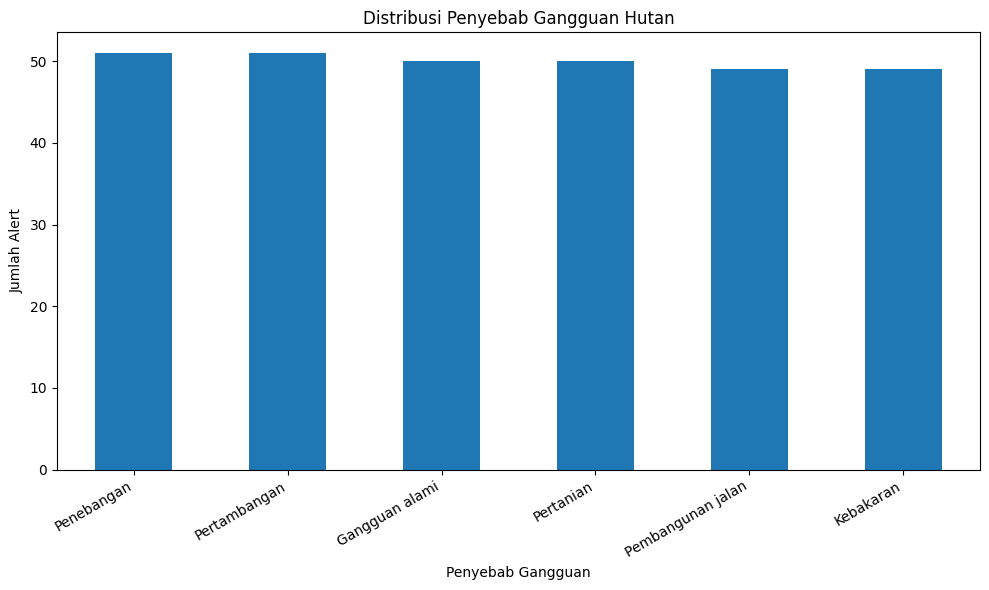

In [ ]:
# Menghitung jumlah alert berdasarkan penyebab
jumlah_penyebab = df["penyebab"].value_counts()

# Membuat grafik batang
plt.figure(figsize=(10, 6))

jumlah_penyebab.plot(kind="bar")

plt.title("Distribusi Penyebab Gangguan Hutan")
plt.xlabel("Penyebab Gangguan")
plt.ylabel("Jumlah Alert")
plt.xticks(rotation=30, ha="right")

plt.tight_layout()
plt.show()

Rata-rata luas gangguan berdasarkan penyebab:


,luas_gangguan_ha
penyebab,
Pertambangan,56.87
Gangguan alami,52.90
Pembangunan jalan,52.52
Pertanian,51.71
Penebangan,47.37
Kebakaran,46.08


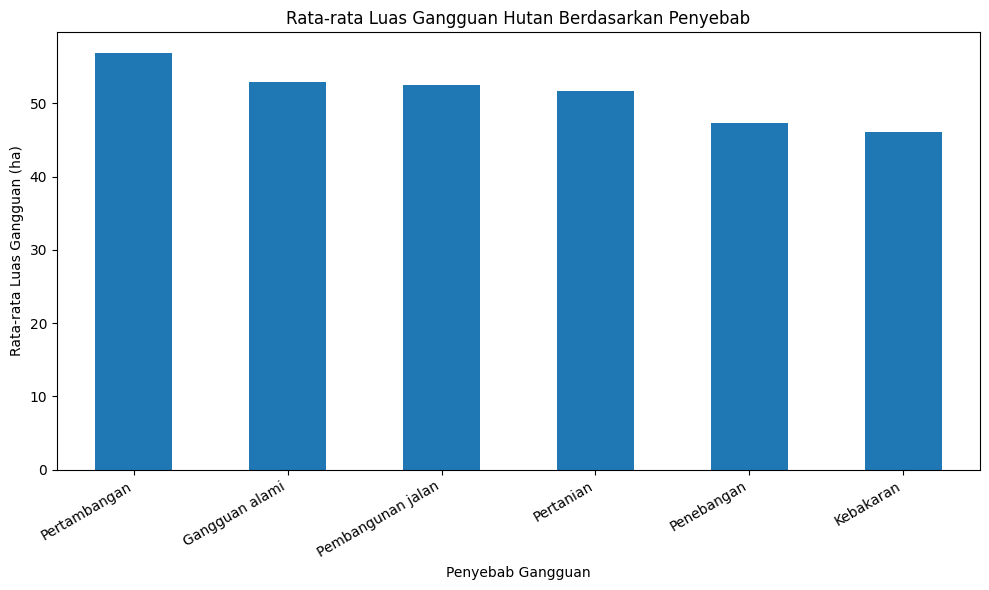

In [ ]:
# Menghitung rata-rata luas gangguan per penyebab
rata_luas = df.groupby("penyebab")["luas_gangguan_ha"].mean()

# Mengurutkan dari luas terbesar
rata_luas = rata_luas.sort_values(ascending=False)

print("Rata-rata luas gangguan berdasarkan penyebab:")
display(rata_luas.round(2))

# Membuat grafik
plt.figure(figsize=(10, 6))

rata_luas.plot(kind="bar")

plt.title("Rata-rata Luas Gangguan Hutan Berdasarkan Penyebab")
plt.xlabel("Penyebab Gangguan")
plt.ylabel("Rata-rata Luas Gangguan (ha)")
plt.xticks(rotation=30, ha="right")

plt.tight_layout()
plt.show()

Rata-rata Confidence Berdasarkan Penyebab:


,confidence
penyebab,
Gangguan alami,79.72
Pertanian,76.08
Pembangunan jalan,74.63
Penebangan,74.55
Kebakaran,73.47
Pertambangan,72.78


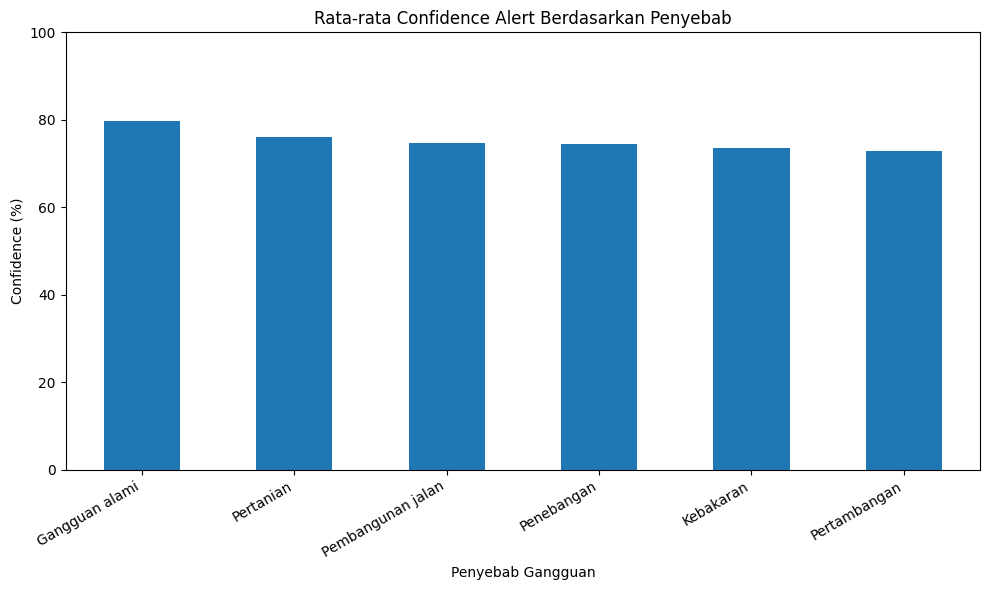

In [ ]:
# Menghitung rata-rata confidence setiap penyebab
rata_confidence = (
    df.groupby("penyebab")["confidence"]
    .mean()
    .sort_values(ascending=False)
)

print("Rata-rata Confidence Berdasarkan Penyebab:")
display((rata_confidence * 100).round(2))

# Membuat grafik
plt.figure(figsize=(10, 6))

(rata_confidence * 100).plot(kind="bar")

plt.title("Rata-rata Confidence Alert Berdasarkan Penyebab")
plt.xlabel("Penyebab Gangguan")
plt.ylabel("Confidence (%)")
plt.xticks(rotation=30, ha="right")
plt.ylim(0, 100)

plt.tight_layout()
plt.show()

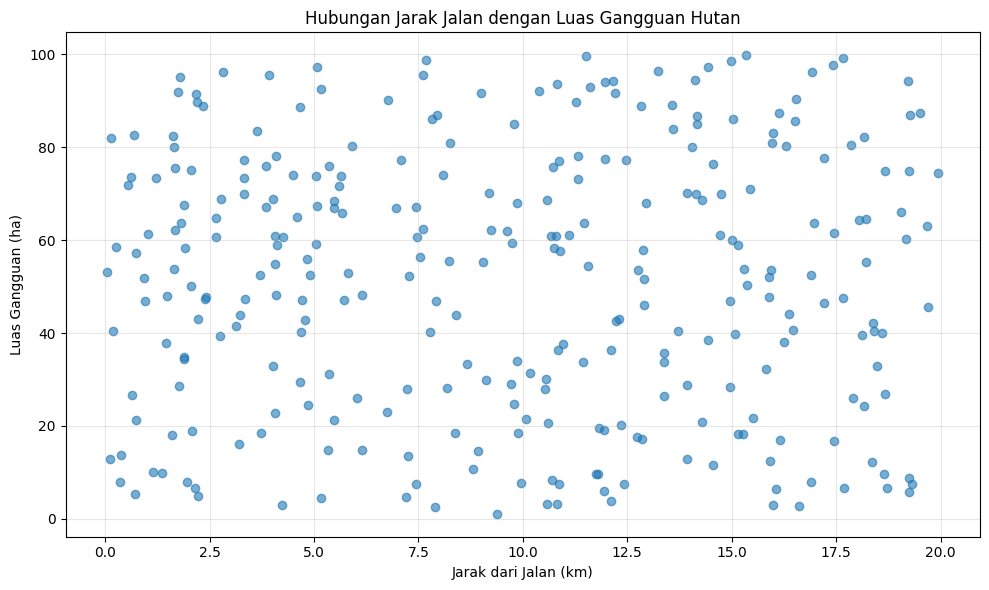

Korelasi jarak jalan dan luas gangguan: -0.007


In [ ]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df["jarak_jalan_km"],
    df["luas_gangguan_ha"],
    alpha=0.6
)

plt.title("Hubungan Jarak Jalan dengan Luas Gangguan Hutan")
plt.xlabel("Jarak dari Jalan (km)")
plt.ylabel("Luas Gangguan (ha)")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

korelasi = df["jarak_jalan_km"].corr(df["luas_gangguan_ha"])

print(f"Korelasi jarak jalan dan luas gangguan: {korelasi:.3f}")

Ringkasan gangguan hutan berdasarkan wilayah:


,jumlah_alert,rata_luas_ha,rata_confidence
wilayah,,,
Kalimantan,82,47.92,0.78
Papua,67,52.29,0.74
Sulawesi,88,53.53,0.76
Sumatra,63,51.34,0.72


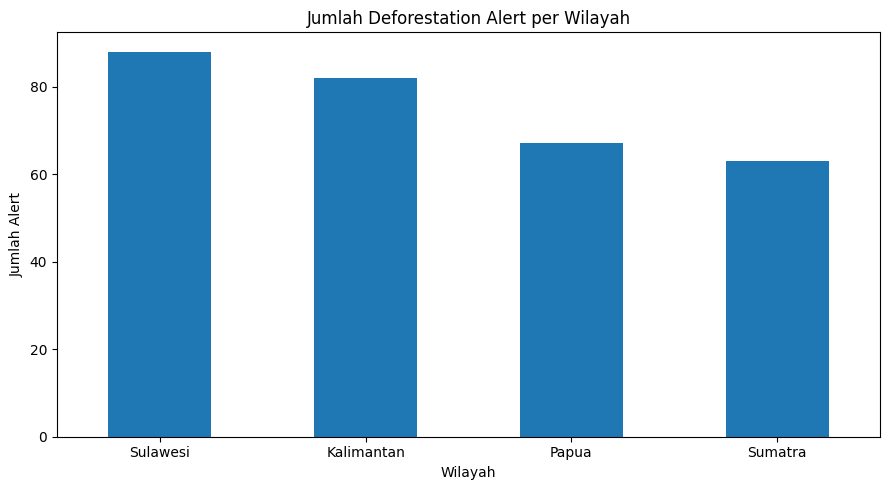

In [ ]:
jumlah_wilayah = df.groupby("wilayah").agg(
    jumlah_alert=("id_alert", "count"),
    rata_luas_ha=("luas_gangguan_ha", "mean"),
    rata_confidence=("confidence", "mean")
)

print("Ringkasan gangguan hutan berdasarkan wilayah:")
display(jumlah_wilayah.round(2))

plt.figure(figsize=(9, 5))

jumlah_wilayah["jumlah_alert"].sort_values(
    ascending=False
).plot(kind="bar")

plt.title("Jumlah Deforestation Alert per Wilayah")
plt.xlabel("Wilayah")
plt.ylabel("Jumlah Alert")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [ ]:
ringkasan = df.groupby("penyebab").agg(
    jumlah_alert=("id_alert", "count"),
    rata_luas_ha=("luas_gangguan_ha", "mean"),
    total_luas_ha=("luas_gangguan_ha", "sum"),
    rata_confidence=("confidence", "mean")
)

ringkasan = ringkasan.sort_values(
    by="jumlah_alert",
    ascending=False
)

display(ringkasan.round(2))

penyebab_terbanyak = ringkasan["jumlah_alert"].idxmax()
luas_rata_tertinggi = ringkasan["rata_luas_ha"].idxmax()

print("Penyebab dengan jumlah alert terbanyak:", penyebab_terbanyak)
print("Penyebab dengan rata-rata luas gangguan tertinggi:", luas_rata_tertinggi)

,jumlah_alert,rata_luas_ha,total_luas_ha,rata_confidence
penyebab,,,,
Pertambangan,51,56.87,2900.61,0.73
Penebangan,51,47.37,2415.74,0.75
Pertanian,50,51.71,2585.62,0.76
Gangguan alami,50,52.90,2645.22,0.80
Kebakaran,49,46.08,2257.72,0.73
Pembangunan jalan,49,52.52,2573.33,0.75


Penyebab dengan jumlah alert terbanyak: Pertambangan
Penyebab dengan rata-rata luas gangguan tertinggi: Pertambangan


In [ ]:
total_alert = len(df)
total_luas = df["luas_gangguan_ha"].sum()
rata_luas = df["luas_gangguan_ha"].mean()
rata_conf = df["confidence"].mean() * 100

wilayah_terbanyak = df["wilayah"].value_counts().idxmax()

print("===== HASIL ANALISIS FOREST DEFORESTATION =====")
print(f"Total alert: {total_alert}")
print(f"Total luas gangguan simulasi: {total_luas:.2f} ha")
print(f"Rata-rata luas gangguan: {rata_luas:.2f} ha")
print(f"Rata-rata confidence: {rata_conf:.2f}%")
print(f"Wilayah dengan alert terbanyak: {wilayah_terbanyak}")
print(f"Penyebab dengan alert terbanyak: {penyebab_terbanyak}")
print(f"Penyebab dengan rata-rata luas terbesar: {luas_rata_tertinggi}")

print("\nCatatan:")
print("Hasil ini berasal dari data simulasi untuk pembelajaran.")
print("Hasil tidak dapat digunakan untuk menyimpulkan kondisi deforestasi nyata.")

===== HASIL ANALISIS FOREST DEFORESTATION =====
Total alert: 300
Total luas gangguan simulasi: 15378.24 ha
Rata-rata luas gangguan: 51.26 ha
Rata-rata confidence: 75.20%
Wilayah dengan alert terbanyak: Sulawesi
Penyebab dengan alert terbanyak: Pertambangan
Penyebab dengan rata-rata luas terbesar: Pertambangan

Catatan:
Hasil ini berasal dari data simulasi untuk pembelajaran.
Hasil tidak dapat digunakan untuk menyimpulkan kondisi deforestasi nyata.


In [ ]:
# Menyimpan seluruh data alert
df.to_csv("webinar5_deforestation_alerts.csv", index=False)

# Menyimpan ringkasan analisis
ringkasan.to_csv("webinar5_ringkasan_analisis.csv")

print("File berhasil dibuat:")
print("1. webinar5_deforestation_alerts.csv")
print("2. webinar5_ringkasan_analisis.csv")

File berhasil dibuat:
1. webinar5_deforestation_alerts.csv
2. webinar5_ringkasan_analisis.csv


In [ ]:
from google.colab import files

files.download("webinar5_deforestation_alerts.csv")
files.download("webinar5_ringkasan_analisis.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import plotly.express as px
import ipywidgets as widgets
from IPython.display import display, clear_output, HTML

print("Library dashboard interaktif siap digunakan!")

Library dashboard interaktif siap digunakan!


In [ ]:
pilihan_wilayah = ["Semua Wilayah"] + sorted(df["wilayah"].unique().tolist())
pilihan_penyebab = ["Semua Penyebab"] + sorted(df["penyebab"].unique().tolist())

filter_wilayah = widgets.Dropdown(
    options=pilihan_wilayah,
    value="Semua Wilayah",
    description="Wilayah:",
    layout=widgets.Layout(width="350px")
)

filter_penyebab = widgets.Dropdown(
    options=pilihan_penyebab,
    value="Semua Penyebab",
    description="Penyebab:",
    layout=widgets.Layout(width="450px")
)

display(filter_wilayah, filter_penyebab)

Dropdown(description='Wilayah:', layout=Layout(width='350px'), options=('Semua Wilayah', np.str_('Kalimantan')…

Dropdown(description='Penyebab:', layout=Layout(width='450px'), options=('Semua Penyebab', np.str_('Gangguan a…

In [ ]:
output_dashboard = widgets.Output()

def tampilkan_dashboard(wilayah, penyebab):
    with output_dashboard:
        clear_output(wait=True)

        data_filter = df.copy()

        if wilayah != "Semua Wilayah":
            data_filter = data_filter[
                data_filter["wilayah"] == wilayah
            ]

        if penyebab != "Semua Penyebab":
            data_filter = data_filter[
                data_filter["penyebab"] == penyebab
            ]

        if data_filter.empty:
            display(HTML(
                "<h3>Data tidak ditemukan</h3>"
                "<p>Coba ubah pilihan filter.</p>"
            ))
            return

        total_alert = len(data_filter)
        total_luas = data_filter["luas_gangguan_ha"].sum()
        rata_luas = data_filter["luas_gangguan_ha"].mean()
        rata_conf = data_filter["confidence"].mean() * 100

        display(HTML(f"""
        <h2>Forest Alert Interactive Dashboard</h2>
        <p>Ringkasan berdasarkan filter yang dipilih.</p>
        <table style="width:100%; text-align:center; border-collapse:collapse">
          <tr>
            <td style="padding:12px; border:1px solid #ccc">
              <b>Total Alert</b><h2>{total_alert}</h2>
            </td>
            <td style="padding:12px; border:1px solid #ccc">
              <b>Total Luas Simulasi</b><h2>{total_luas:.2f} ha</h2>
            </td>
            <td style="padding:12px; border:1px solid #ccc">
              <b>Rata-rata Luas</b><h2>{rata_luas:.2f} ha</h2>
            </td>
            <td style="padding:12px; border:1px solid #ccc">
              <b>Rata-rata Confidence</b><h2>{rata_conf:.2f}%</h2>
            </td>
          </tr>
        </table>
        """))

        # Grafik 1: rata-rata luas gangguan berdasarkan penyebab
        ringkasan_grafik = (
            data_filter.groupby("penyebab", as_index=False)
            ["luas_gangguan_ha"].mean()
            .sort_values("luas_gangguan_ha", ascending=False)
        )

        fig1 = px.bar(
            ringkasan_grafik,
            x="penyebab",
            y="luas_gangguan_ha",
            title="Rata-rata Luas Gangguan per Penyebab",
            labels={
                "penyebab": "Penyebab Gangguan",
                "luas_gangguan_ha": "Rata-rata Luas (ha)"
            },
            color="luas_gangguan_ha"
        )
        fig1.update_layout(xaxis_tickangle=-30)
        fig1.show()

        # Grafik 2: hubungan jarak jalan dan luas gangguan
        fig2 = px.scatter(
            data_filter,
            x="jarak_jalan_km",
            y="luas_gangguan_ha",
            color="penyebab",
            hover_data=["id_alert", "wilayah", "confidence"],
            title="Jarak Jalan dan Luas Gangguan",
            labels={
                "jarak_jalan_km": "Jarak dari Jalan (km)",
                "luas_gangguan_ha": "Luas Gangguan (ha)",
                "penyebab": "Penyebab"
            }
        )
        fig2.show()

        # Tabel data yang telah difilter
        display(HTML("<h3>Data Alert yang Ditampilkan</h3>"))
        display(
            data_filter.head(15).reset_index(drop=True)
            .round(2)
        )

        print(
            f"Menampilkan {min(len(data_filter), 15)} dari "
            f"{len(data_filter)} baris hasil filter."
        )

def saat_filter_berubah(change):
    tampilkan_dashboard(
        filter_wilayah.value,
        filter_penyebab.value
    )

filter_wilayah.observe(saat_filter_berubah, names="value")
filter_penyebab.observe(saat_filter_berubah, names="value")

display(output_dashboard)

tampilkan_dashboard(
    filter_wilayah.value,
    filter_penyebab.value
)

Output()

In [ ]:
evaluasi_hci = pd.DataFrame({
    "Aspek HCI": [
        "Kejelasan informasi",
        "Konsistensi antarmuka",
        "Umpan balik pengguna",
        "Kemudahan penggunaan",
        "Penanganan data kosong",
        "Visualisasi interaktif"
    ],
    "Penerapan": [
        "Grafik dan indikator memiliki judul serta label",
        "Filter ditempatkan secara konsisten di bagian atas",
        "Dashboard berubah ketika filter diubah",
        "Pengguna memilih opsi dari dropdown",
        "Pesan ditampilkan jika hasil filter kosong",
        "Grafik mendukung hover untuk melihat detail"
    ]
})

display(evaluasi_hci)

,Aspek HCI,Penerapan
0,Kejelasan informasi,Grafik dan indikator memiliki judul serta label
1,Konsistensi antarmuka,Filter ditempatkan secara konsisten di bagian ...
2,Umpan balik pengguna,Dashboard berubah ketika filter diubah
3,Kemudahan penggunaan,Pengguna memilih opsi dari dropdown
4,Penanganan data kosong,Pesan ditampilkan jika hasil filter kosong
5,Visualisasi interaktif,Grafik mendukung hover untuk melihat detail
